In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
import torch
import torch.utils.data as data
import torchvision
import torchvision.transforms.v2 as tfs_v2
import torch.nn as nn
import torch.optim as optim

In [2]:
class AutoEncoderMNIST(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ELU(inplace=True),
            nn.BatchNorm1d(128),
            nn.Linear(128, 64),
            nn.ELU(inplace=True),
            nn.BatchNorm1d(64)
        )

        self.h_mean = nn.Linear(64, self.hidden_dim)
        self.h_log_var = nn.Linear(64, self.hidden_dim)

        self.decoder = nn.Sequential(
            nn.Linear(self.hidden_dim, 64),
            nn.ELU(inplace=True),
            nn.BatchNorm1d(64),
            nn.Linear(64, 128),
            nn.ELU(inplace=True),
            nn.BatchNorm1d(128),
            nn.Linear(128, output_dim),
            nn.Sigmoid()
        )

    def forward(self, x):
        enc = self.encoder(x)

        h_mean = self.h_mean(enc)
        h_log_var = self.h_log_var(enc)

        noise = torch.normal(mean=torch.zeros_like(h_mean), std=torch.ones_like(h_log_var))
        h = noise * torch.exp(h_log_var / 2) + h_mean
        x = self.decoder(h)

        return x, h, h_mean, h_log_var


In [3]:
class VAELoss(nn.Module):
    def forward(self, x, y, h_mean, h_log_var):
        img_loss = torch.sum(torch.square(x - y), dim=-1)
        kl_loss = -0.5 * torch.sum(1 + h_log_var - torch.square(h_mean) - torch.exp(h_log_var), dim=-1)
        return torch.mean(img_loss + kl_loss)



100%|██████████| 9.91M/9.91M [00:00<00:00, 154MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 51.9MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 51.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.58MB/s]
Epoch [5/5], loss_mean=40.397: 100%|██████████| 600/600 [00:24<00:00, 24.14it/s]


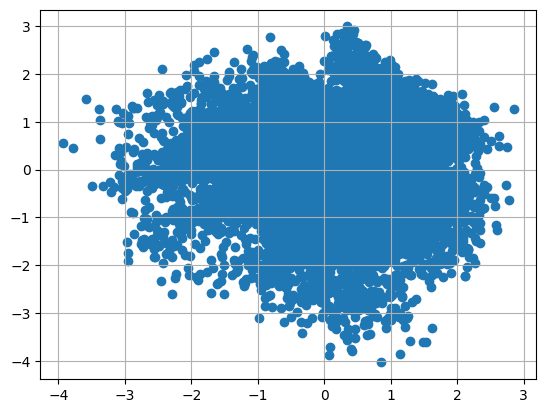

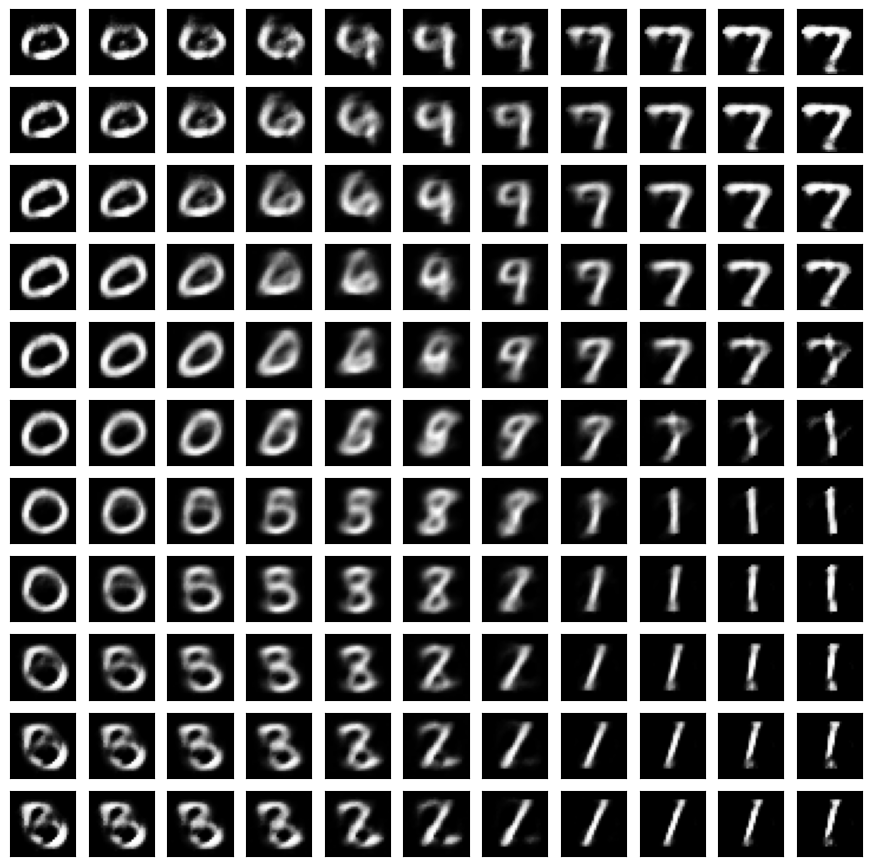

In [4]:
model = AutoEncoderMNIST(784, 784, 2)
transforms = tfs_v2.Compose([tfs_v2.ToImage(), tfs_v2.ToDtype(dtype=torch.float32, scale=True),
                             tfs_v2.Lambda(lambda _img: _img.ravel())])

d_train = torchvision.datasets.MNIST(r'C:\datasets\mnist', download=True, train=True, transform=transforms)
train_data = data.DataLoader(d_train, batch_size=100, shuffle=True)

optimizer = optim.Adam(params=model.parameters(), lr=0.001)
loss_func = VAELoss()

epochs = 5
model.train()

for _e in range(epochs):
    loss_mean = 0
    lm_count = 0

    train_tqdm = tqdm(train_data, leave=True)
    for x_train, y_train in train_tqdm:
        predict, _, h_mean, h_log_var = model(x_train)
        loss = loss_func(predict, x_train, h_mean, h_log_var)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

st = model.state_dict()
torch.save(st, 'model_vae_3.tar')

# st = torch.load('model_vae.tar', weights_only=True)
# model.load_state_dict(st)

model.eval()

d_test = torchvision.datasets.MNIST(r'C:\datasets\mnist', download=True, train=False, transform=transforms)
x_data = transforms(d_test.data).view(len(d_test), -1)

_, h, _, _ = model(x_data)
h = h.detach().numpy()

plt.scatter(h[:, 0], h[:, 1])
plt.grid()


n = 5
total = 2*n+1

plt.figure(figsize=(total, total))

num = 1
for i in range(-n, n+1):
    for j in range(-n, n+1):
        ax = plt.subplot(total, total, num)
        num += 1
        h = torch.tensor([3*i/n, 3*j/n], dtype=torch.float32)
        predict = model.decoder(h.unsqueeze(0))
        predict = predict.detach().squeeze(0).view(28, 28)
        dec_img = predict.numpy()

        plt.imshow(dec_img, cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

plt.show()